## 1. Setup, Drive folder, config

In [ ]:
!pip -q install -U transformers librosa soundfile scikit-learn seaborn tqdm

import os, sys, json, math, time, shutil, random
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             classification_report, confusion_matrix)

from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/Auralis AI')
DIRS = {k: ROOT / k for k in ['data', 'checkpoints', 'best_model', 'results', 'logs']}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), 'No GPU. Runtime > Change runtime type > T4 GPU'
device = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0))

CFG = dict(
    seed=42,
    backbone='facebook/wav2vec2-base',   # for max accuracy later try 'facebook/wav2vec2-large-960h-lv60-self'
                                         # (then use batch_size=4, grad_accum=8, lr_backbone=1.5e-5, grad_ckpt=True)
    n_test_actors=5, n_val_actors=3,     # 5/24 = 21% test, 3 val actors carved out of the other 19
    epochs=40, patience=10,
    batch_size=16, grad_accum=2,         # effective batch = 32
    lr_backbone=3e-5, lr_head=5e-4, weight_decay=0.01, warmup_frac=0.1,
    label_smoothing=0.1, dropout=0.3, mask_time_prob=0.05,
    grad_ckpt=False, num_workers=2,
    resume=True, resume_every=3,         # epochs between resume-checkpoint saves (they are ~1 GB)
)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG['seed'])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 80.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 5.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Mounted at /content/drive
GPU: Tesla T4


## 2. Core module (written to Drive so the portal backend can reuse it)
Audio utilities, augmentations, the model class and the inference function live in one file, `auralis_core.py`. The training notebook and the future web backend import the same code, so training and deployment can't drift apart.

In [ ]:
%%writefile /content/auralis_core.py
# auralis_core.py : audio utils, augmentation, model, inference for Auralis AI
import json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from scipy.signal import butter, sosfilt, fftconvolve
from transformers import Wav2Vec2Config, Wav2Vec2Model

SR = 16000
MAX_SEC = 4.0
MAX_LEN = int(SR * MAX_SEC)

# ------------------------------------------------------------------ audio utils
def load_wave(path, trim_db=30):
    # load as 16 kHz mono and trim leading/trailing silence
    import librosa
    x, _ = librosa.load(str(path), sr=SR, mono=True)
    if trim_db:
        y, _ = librosa.effects.trim(x, top_db=trim_db)
        if len(y) >= SR // 10:
            x = y
    return x.astype(np.float32)

def normalize(x):
    # per-utterance zero-mean / unit-variance (what Wav2Vec2 expects)
    x = x - x.mean()
    return (x / np.sqrt(x.var() + 1e-7)).astype(np.float32)

def crop_or_pad_start(x, max_len=MAX_LEN, rng=None):
    # random crop when training (rng given), center crop otherwise. Padding is done after normalization.
    n = len(x)
    if n > max_len:
        start = int(rng.integers(0, n - max_len + 1)) if rng is not None else (n - max_len) // 2
        x = x[start:start + max_len]
    return x

# ------------------------------------------------------------------ augmentations / corruptions
def _rms(x):
    return float(np.sqrt(np.mean(x ** 2) + 1e-12))

def colored_noise(n, kind, rng):
    white = rng.standard_normal(n).astype(np.float32)
    if kind == 'white':
        return white
    spec = np.fft.rfft(white)
    f = np.fft.rfftfreq(n)
    f[0] = f[1]
    power = {'pink': 1.0, 'brown': 2.0}[kind]
    spec = spec / (f ** (power / 2.0))
    return np.fft.irfft(spec, n).astype(np.float32)

def add_noise(x, snr_db, kind, rng):
    noise = colored_noise(len(x), kind, rng)
    noise = noise * (_rms(x) / (_rms(noise) * 10 ** (snr_db / 20.0)))
    return (x + noise).astype(np.float32)

def add_reverb(x, rt60, rng):
    # synthetic room impulse response: direct path + exponentially decaying noise tail
    n = int(rt60 * SR)
    t = np.arange(n) / SR
    ir = rng.standard_normal(n).astype(np.float32) * np.exp(-6.9 * t / rt60) * 0.5
    ir[0] = 1.0
    return fftconvolve(x, ir)[:len(x)].astype(np.float32)

def bandpass(x, lo, hi):
    sos = butter(6, [lo / (SR / 2), hi / (SR / 2)], btype='band', output='sos')
    return sosfilt(sos, x).astype(np.float32)

def lowpass(x, cutoff):
    sos = butter(6, cutoff / (SR / 2), btype='low', output='sos')
    return sosfilt(sos, x).astype(np.float32)

def clip_distort(x, factor):
    peak = float(np.max(np.abs(x))) + 1e-9
    return np.clip(x / peak * factor, -1.0, 1.0).astype(np.float32)

def change_speed(x, factor):
    n = int(len(x) / factor)
    return np.interp(np.linspace(0, len(x) - 1, n), np.arange(len(x)), x).astype(np.float32)

def augment_train(x, rng):
    # random chain of real-world degradations. Probabilities chosen so ~25% of samples stay clean.
    if rng.random() < 0.30:
        x = change_speed(x, rng.uniform(0.95, 1.05))
    if rng.random() < 0.30:
        x = add_reverb(x, rng.uniform(0.1, 0.8), rng)
    r = rng.random()
    if r < 0.10:
        x = bandpass(x, 300, 3400)                       # telephone
    elif r < 0.18:
        x = lowpass(x, rng.uniform(3500, 7000))          # cheap mic / low bandwidth
    if rng.random() < 0.65:
        x = add_noise(x, rng.uniform(3, 30), str(rng.choice(['white', 'pink', 'brown'])), rng)
    if rng.random() < 0.10:
        x = clip_distort(x, rng.uniform(2, 6))
    return x

def robustness_scenarios():
    # fixed test-time corruptions for the robustness benchmark: name -> fn(x, rng)
    return {
        'clean': None,
        'white noise 20 dB': lambda x, r: add_noise(x, 20, 'white', r),
        'white noise 10 dB': lambda x, r: add_noise(x, 10, 'white', r),
        'white noise 5 dB':  lambda x, r: add_noise(x, 5, 'white', r),
        'white noise 0 dB':  lambda x, r: add_noise(x, 0, 'white', r),
        'pink noise 10 dB':  lambda x, r: add_noise(x, 10, 'pink', r),
        'brown noise 10 dB': lambda x, r: add_noise(x, 10, 'brown', r),
        'reverb RT60 0.4 s': lambda x, r: add_reverb(x, 0.4, r),
        'reverb RT60 0.8 s': lambda x, r: add_reverb(x, 0.8, r),
        'telephone 300-3400 Hz': lambda x, r: bandpass(x, 300, 3400),
        'low-pass 4 kHz':    lambda x, r: lowpass(x, 4000),
        'clipping (x4)':     lambda x, r: clip_distort(x, 4.0),
        'speed 0.9x':        lambda x, r: change_speed(x, 0.9),
        'speed 1.1x':        lambda x, r: change_speed(x, 1.1),
        'noise 10 dB + reverb 0.4 s': lambda x, r: add_noise(add_reverb(x, 0.4, r), 10, 'pink', r),
    }

# ------------------------------------------------------------------ model
class AttentiveStatsPooling(nn.Module):
    # attention-weighted mean + std over time; also returns the attention weights (explainability)
    def __init__(self, dim, hidden=128):
        super().__init__()
        self.att = nn.Sequential(nn.Linear(dim, hidden), nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, x, mask):
        x = x.float()
        a = self.att(x).squeeze(-1).masked_fill(~mask, -1e4)
        w = torch.softmax(a, dim=1).unsqueeze(-1)
        mean = (w * x).sum(1)
        var = (w * (x - mean.unsqueeze(1)) ** 2).sum(1)
        return torch.cat([mean, torch.sqrt(var + 1e-5)], dim=-1), w.squeeze(-1)

class AuralisModel(nn.Module):
    # Wav2Vec2 backbone -> learnable weighted sum of all layers -> projection -> attentive stats pooling -> classifier
    def __init__(self, backbone, num_labels, load_pretrained=True, proj_dim=256,
                 dropout=0.3, mask_time_prob=0.05):
        super().__init__()
        cfg = backbone if isinstance(backbone, Wav2Vec2Config) else Wav2Vec2Config.from_pretrained(backbone)
        cfg.mask_time_prob = mask_time_prob        # SpecAugment-style time masking (training only)
        cfg.mask_time_length = 10
        cfg.mask_feature_prob = 0.0
        cfg.layerdrop = 0.0
        cfg.hidden_dropout = 0.1
        cfg.attention_dropout = 0.1
        cfg.feat_proj_dropout = 0.05
        if load_pretrained and isinstance(backbone, str):
            self.backbone = Wav2Vec2Model.from_pretrained(backbone, config=cfg)
        else:
            self.backbone = Wav2Vec2Model(cfg)
        self.backbone.freeze_feature_encoder()     # CNN feature extractor stays frozen (standard practice)
        H = cfg.hidden_size
        self.layer_w = nn.Parameter(torch.zeros(cfg.num_hidden_layers + 1))
        self.proj = nn.Sequential(nn.Linear(H, proj_dim), nn.GELU(), nn.Dropout(dropout))
        self.pool = AttentiveStatsPooling(proj_dim)
        self.cls = nn.Sequential(nn.LayerNorm(proj_dim * 2), nn.Dropout(dropout),
                                 nn.Linear(proj_dim * 2, proj_dim), nn.GELU(),
                                 nn.Dropout(dropout), nn.Linear(proj_dim, num_labels))

    def forward(self, wave, lengths, return_attention=False):
        B, N = wave.shape
        amask = (torch.arange(N, device=wave.device)[None, :] < lengths[:, None]).long()
        use_mask = self.backbone.config.feat_extract_norm == 'layer'   # base models: no attention mask
        out = self.backbone(wave, attention_mask=amask if use_mask else None, output_hidden_states=True)
        hs = torch.stack(out.hidden_states, dim=0)                      # L, B, T, H
        w = torch.softmax(self.layer_w, dim=0).to(hs.dtype)
        x = (w.view(-1, 1, 1, 1) * hs).sum(0)                           # B, T, H
        T = x.shape[1]
        flen = self.backbone._get_feat_extract_output_lengths(lengths).clamp(max=T)
        fmask = torch.arange(T, device=wave.device)[None, :] < flen[:, None]
        pooled, att = self.pool(self.proj(x), fmask)
        logits = self.cls(pooled)
        return (logits, att) if return_attention else logits

# ------------------------------------------------------------------ inference (used by the portal)
def load_auralis(root, device=None):
    root = Path(root)
    cfg = json.load(open(root / 'best_model' / 'auralis_config.json'))
    model = AuralisModel(cfg['backbone'], len(cfg['labels']), load_pretrained=False)
    ckpt = torch.load(root / 'best_model' / 'auralis_best.pt', map_location='cpu', weights_only=False)
    model.load_state_dict(ckpt['model'])
    device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
    return model.to(device).eval(), cfg

@torch.no_grad()
def predict(model, cfg, audio, stride_sec=2.0, batch=16):
    # audio: file path or 16 kHz float array. Long audio is split into overlapping 4 s windows;
    # returns the overall emotion (mean of window probabilities) plus a per-window timeline.
    device = next(model.parameters()).device
    x = load_wave(audio) if isinstance(audio, (str, Path)) else np.asarray(audio, dtype=np.float32)
    n = len(x)
    if n <= MAX_LEN:
        starts = [0]
    else:
        starts = list(range(0, n - MAX_LEN + 1, int(stride_sec * SR)))
        if starts[-1] + MAX_LEN < n:
            starts.append(n - MAX_LEN)
    segs, lens = [], []
    for s in starts:
        seg = normalize(x[s:s + MAX_LEN])
        pad = np.zeros(MAX_LEN, np.float32)
        pad[:len(seg)] = seg
        segs.append(pad); lens.append(len(seg))
    model.eval()
    probs = []
    for i in range(0, len(segs), batch):
        xb = torch.from_numpy(np.stack(segs[i:i + batch])).to(device)
        lb = torch.tensor(lens[i:i + batch]).to(device)
        probs.append(torch.softmax(model(xb, lb).float(), dim=-1).cpu().numpy())
    probs = np.concatenate(probs)
    mean = probs.mean(0)
    labels = cfg['labels']
    k = int(mean.argmax())
    return {
        'emotion': labels[k],
        'confidence': float(mean[k]),
        'probabilities': {l: float(p) for l, p in zip(labels, mean)},
        'duration_sec': n / SR,
        'timeline': [{'start': s / SR, 'end': min(s + MAX_LEN, n) / SR,
                      'emotion': labels[int(p.argmax())], 'confidence': float(p.max())}
                     for s, p in zip(starts, probs)],
    }

Writing /content/auralis_core.py


In [ ]:
import importlib
sys.path.insert(0, '/content')
import auralis_core
importlib.reload(auralis_core)
from auralis_core import *
shutil.copy('/content/auralis_core.py', ROOT / 'auralis_core.py')
print('auralis_core.py saved to', ROOT)

auralis_core.py saved to /content/drive/MyDrive/Auralis AI


## 3. RAVDESS: download, parse labels, speaker-independent split
Uses the **speech** portion only (1,440 files = 24 actors x 60). Filename format: `modality-channel-emotion-intensity-statement-repetition-actor.wav`.
If the download fails, upload `Audio_Speech_Actors_01-24.zip` (from Zenodo or Kaggle) to `MyDrive/Auralis AI/data/` and re-run.

In [ ]:
import zipfile

ZIP = DIRS['data'] / 'Audio_Speech_Actors_01-24.zip'
EXTRACT_DIR = DIRS['data'] / 'RAVDESS'          # Auralis AI/data/RAVDESS/

def zip_ok(p):
    return p.exists() and p.stat().st_size > 100e6 and zipfile.is_zipfile(p)

if not zip_ok(ZIP):
    print('Zip missing/corrupt, downloading...')
    ZIP.unlink(missing_ok=True)
    !wget -q --show-progress -O "{ZIP}" "https://zenodo.org/record/1188976/files/Audio_Speech_Actors_01-24.zip?download=1"
assert zip_ok(ZIP), 'Zip invalid. Download Audio_Speech_Actors_01-24.zip manually and upload it to Auralis AI/data/'

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
if len(list(EXTRACT_DIR.rglob('*.wav'))) < 1440:          # extract only if incomplete
    with zipfile.ZipFile(ZIP) as z:
        for member in tqdm(z.namelist(), desc='extracting'):
            z.extract(member, EXTRACT_DIR)
print('wav files found:', len(list(EXTRACT_DIR.rglob('*.wav'))))   # expect 1440

EMOTIONS = {1: 'neutral', 2: 'calm', 3: 'happy', 4: 'sad', 5: 'angry', 6: 'fearful', 7: 'disgust', 8: 'surprised'}
LABELS = [EMOTIONS[i] for i in range(1, 9)]

rows = []
for p in sorted(EXTRACT_DIR.rglob('*.wav')):
    parts = p.stem.split('-')
    if len(parts) != 7:
        continue
    mod, voc, emo, inten, stmt, rep, actor = map(int, parts)
    if mod != 3 or voc != 1:          # audio-only, speech
        continue
    rows.append(dict(path=str(p), emotion=EMOTIONS[emo], label=emo - 1, intensity=inten,
                     statement=stmt, repetition=rep, actor=actor))
df = pd.DataFrame(rows)
assert len(df) == 1440, f'expected 1440 speech files, found {len(df)}'
print(df.emotion.value_counts().to_string())

extracting:   0%|          | 0/1464 [00:00<?, ?it/s]

wav files found: 1440
emotion
calm         192
happy        192
sad          192
angry        192
disgust      192
fearful      192
surprised    192
neutral       96


In [ ]:
# ---- speaker-independent split (actors never overlap between train / val / test)
rng = np.random.RandomState(CFG['seed'])
males   = [a for a in range(1, 25) if a % 2 == 1]
females = [a for a in range(1, 25) if a % 2 == 0]
pick = lambda pool, k: [int(a) for a in rng.choice(pool, k, replace=False)]

test_actors = sorted(pick(males, 2) + pick(females, 3))                       # 5 actors  (~21%)
rest_m = [a for a in males if a not in test_actors]
rest_f = [a for a in females if a not in test_actors]
val_actors = sorted(pick(rest_m, 1) + pick(rest_f, 2))                        # 3 actors, from the train pool
train_actors = sorted(a for a in range(1, 25) if a not in test_actors + val_actors)   # 16 actors

assert not (set(train_actors) & set(val_actors)) and not (set(train_actors) & set(test_actors)) \
       and not (set(val_actors) & set(test_actors))
df['split'] = df.actor.map(lambda a: 'test' if a in test_actors else 'val' if a in val_actors else 'train')
print('train actors:', train_actors); print('val actors:', val_actors); print('test actors:', test_actors)
print(df.split.value_counts().to_string())

train actors: [1, 4, 5, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 23, 24]
val actors: [3, 6, 14]
test actors: [2, 19, 20, 21, 22]
split
train    960
test     300
val      180


In [ ]:
# ---- load + resample all audio once (RAVDESS is 48 kHz -> 16 kHz)
waves = [load_wave(p) for p in tqdm(df.path, desc='loading audio')]
df['dur'] = [len(w) / SR for w in waves]
print(df.dur.describe().round(2).to_string())
print(f'clips longer than {MAX_SEC}s (random-cropped in training): {(df.dur > MAX_SEC).mean():.1%}')

def subset(split):
    idx = df.index[df.split == split].tolist()
    return [waves[i] for i in idx], df.label.values[idx]

(w_tr, y_tr), (w_va, y_va), (w_te, y_te) = subset('train'), subset('val'), subset('test')
counts = np.bincount(y_tr, minlength=8)
class_weights = torch.tensor(counts.sum() / (8 * counts), dtype=torch.float32)
print('train class counts:', dict(zip(LABELS, counts.tolist())))

loading audio:   0%|          | 0/1440 [00:00<?, ?it/s]

count    1440.00
mean        1.90
std         0.42
min         1.15
25%         1.60
50%         1.79
75%         2.11
max         4.25
clips longer than 4.0s (random-cropped in training): 0.1%
train class counts: {'neutral': 64, 'calm': 128, 'happy': 128, 'sad': 128, 'angry': 128, 'fearful': 128, 'disgust': 128, 'surprised': 128}


## 4. Dataset and dataloaders

In [ ]:
class EmoDataset(Dataset):
    def __init__(self, waves, labels, train=False, corrupt=None):
        self.waves, self.labels, self.train, self.corrupt = waves, labels, train, corrupt
    def __len__(self):
        return len(self.waves)
    def __getitem__(self, i):
        x = self.waves[i]
        if self.train:
            rng = np.random.default_rng()                      # fresh randomness every call
            x = augment_train(x, rng)
            x = crop_or_pad_start(x, MAX_LEN, rng)
        else:
            rng = np.random.default_rng(1000 + i)              # deterministic eval corruption
            if self.corrupt is not None:
                x = self.corrupt(x, rng)
            x = crop_or_pad_start(x, MAX_LEN, None)
        L = len(x)
        x = normalize(x)
        pad = np.zeros(MAX_LEN, np.float32)
        pad[:L] = x
        return torch.from_numpy(pad), L, int(self.labels[i])

def make_loader(waves, labels, train=False, corrupt=None):
    ds = EmoDataset(waves, labels, train, corrupt)
    return DataLoader(ds, batch_size=CFG['batch_size'] * (1 if train else 2), shuffle=train, drop_last=train,
                      num_workers=CFG['num_workers'], pin_memory=True)

train_loader = make_loader(w_tr, y_tr, train=True)
val_loader   = make_loader(w_va, y_va)
test_loader  = make_loader(w_te, y_te)

# sanity check: one batch
xb, Lb, yb = next(iter(train_loader))
print(xb.shape, Lb[:4], yb[:4])

torch.Size([16, 64000]) tensor([32939, 37888, 30208, 41984]) tensor([4, 6, 5, 1])


## 5. Model, optimizer, scheduler

In [ ]:
model = AuralisModel(CFG['backbone'], len(LABELS), dropout=CFG['dropout'],
                     mask_time_prob=CFG['mask_time_prob']).to(device)
if CFG['grad_ckpt']:
    model.backbone.gradient_checkpointing_enable()

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'params: {n_total/1e6:.1f}M total, {n_train/1e6:.1f}M trainable')

bb_params   = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith('backbone.')]
head_params = [p for n, p in model.named_parameters() if not n.startswith('backbone.')]
opt = torch.optim.AdamW([{'params': bb_params,   'lr': CFG['lr_backbone']},
                         {'params': head_params, 'lr': CFG['lr_head']}], weight_decay=CFG['weight_decay'])

steps_per_epoch = math.ceil(len(train_loader) / CFG['grad_accum'])
total_steps = steps_per_epoch * CFG['epochs']
sched = get_cosine_schedule_with_warmup(opt, int(CFG['warmup_frac'] * total_steps), total_steps)
scaler = torch.amp.GradScaler('cuda')

crit_train = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=CFG['label_smoothing'])
crit_eval  = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    P, Y, loss_sum, n = [], [], 0.0, 0
    for x, L, y in loader:
        x, L, y = x.to(device, non_blocking=True), L.to(device), y.to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x, L)
        logits = logits.float()
        loss_sum += crit_eval(logits, y).item() * len(y); n += len(y)
        P.append(logits.argmax(-1).cpu()); Y.append(y.cpu())
    P, Y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    return dict(loss=loss_sum / n, acc=accuracy_score(Y, P), f1=f1_score(Y, P, average='macro'),
                uar=balanced_accuracy_score(Y, P), preds=P, labels=Y)

def safe_save(obj, path):
    tmp = str(path) + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)      # atomic: a Colab disconnect mid-write never corrupts the old file

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

params: 94.7M total, 90.5M trainable


## 6. Training
Best model is chosen by **validation macro-F1** and saved to `best_model/auralis_best.pt`. If Colab disconnects, just re-run the notebook: training resumes from `checkpoints/last.pt`.

epoch 1/40:   0%|          | 0/60 [00:00<?, ?it/s]

ep 01 | train 2.106 | val loss 2.029 acc 0.294 F1 0.205 | 23s <- best


epoch 2/40:   0%|          | 0/60 [00:00<?, ?it/s]

ep 02 | train 2.016 | val loss 1.730 acc 0.433 F1 0.389 | 39s <- best


epoch 3/40:   0%|          | 0/60 [00:00<?, ?it/s]

...

ep 21 | train 0.650 | val loss 0.649 acc 0.828 F1 0.813 | 22s 


epoch 22/40:   0%|          | 0/60 [00:00<?, ?it/s]

ep 22 | train 0.631 | val loss 0.752 acc 0.778 F1 0.745 | 21s 


epoch 23/40:   0%|          | 0/60 [00:00<?, ?it/s]

ep 23 | train 0.626 | val loss 0.731 acc 0.794 F1 0.764 | 22s 
Early stopping (no val F1 improvement for 10 epochs)


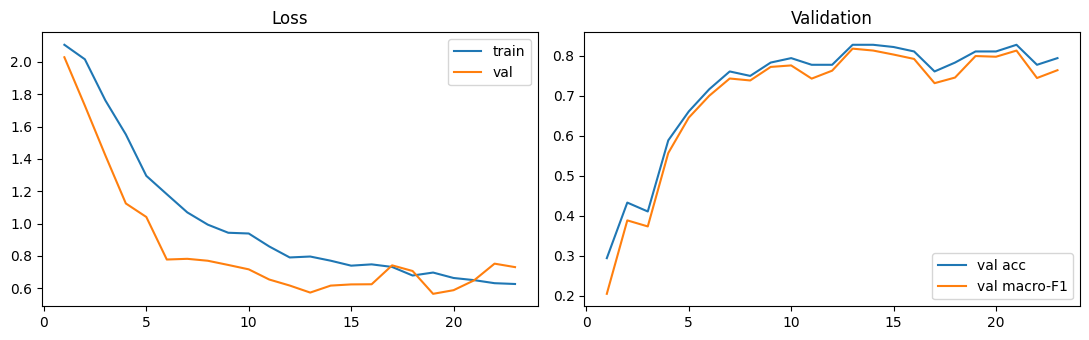

In [ ]:
BEST = DIRS['best_model'] / 'auralis_best.pt'
LAST = DIRS['checkpoints'] / 'last.pt'
history, best_f1, bad_epochs, start_epoch = [], -1.0, 0, 0

if CFG['resume'] and LAST.exists():
    ck = torch.load(LAST, map_location='cpu', weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    history, best_f1, bad_epochs, start_epoch = ck['history'], ck['best_f1'], ck['bad_epochs'], ck['epoch'] + 1
    print(f'Resumed from epoch {start_epoch} (best val F1 so far {best_f1:.4f})')

for epoch in range(start_epoch, CFG['epochs']):
    model.train(); t0 = time.time(); run_loss = 0.0
    opt.zero_grad(set_to_none=True)
    for step, (x, L, y) in enumerate(tqdm(train_loader, desc=f'epoch {epoch+1}/{CFG["epochs"]}', leave=False)):
        x, L, y = x.to(device, non_blocking=True), L.to(device), y.to(device)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x, L)
        loss = crit_train(logits.float(), y) / CFG['grad_accum']
        scaler.scale(loss).backward()
        run_loss += loss.item() * CFG['grad_accum']
        if (step + 1) % CFG['grad_accum'] == 0 or step + 1 == len(train_loader):
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); sched.step()

    va = evaluate(model, val_loader)
    rec = dict(epoch=epoch + 1, train_loss=float(run_loss / len(train_loader)), val_loss=float(va['loss']),
               val_acc=float(va['acc']), val_f1=float(va['f1']), val_uar=float(va['uar']), secs=float(time.time() - t0))
    history.append(rec)
    improved = va['f1'] > best_f1
    if improved:
        best_f1, bad_epochs = float(va['f1']), 0
        safe_save({'model': model.state_dict(), 'epoch': epoch + 1, 'val_f1': best_f1, 'labels': LABELS}, BEST)
    else:
        bad_epochs += 1
    print(f"ep {epoch+1:02d} | train {rec['train_loss']:.3f} | val loss {rec['val_loss']:.3f} "
          f"acc {rec['val_acc']:.3f} F1 {rec['val_f1']:.3f} | {rec['secs']:.0f}s {'<- best' if improved else ''}")
    pd.DataFrame(history).to_csv(DIRS['logs'] / 'training_history.csv', index=False)

    if (epoch + 1) % CFG['resume_every'] == 0:
        safe_save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                   'scaler': scaler.state_dict(), 'history': history, 'best_f1': best_f1,
                   'bad_epochs': bad_epochs, 'epoch': epoch}, LAST)
    if bad_epochs >= CFG['patience']:
        print(f'Early stopping (no val F1 improvement for {CFG["patience"]} epochs)')
        break

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(h.epoch, h.val_acc, label='val acc'); ax[1].plot(h.epoch, h.val_f1, label='val macro-F1'); ax[1].set_title('Validation'); ax[1].legend()
plt.tight_layout(); plt.savefig(DIRS['results'] / 'training_curves.png', dpi=150); plt.show()

## 7. Final evaluation on the held-out test actors
The test set is used **once**, with the best-validation checkpoint.

Loaded best checkpoint from epoch 13 (val macro-F1 0.8181)

VAL  | acc 0.8278  macro-F1 0.8181  UAR 0.8385
TEST | acc 0.7467  macro-F1 0.7443  UAR 0.7562
              precision    recall  f1-score   support

     neutral      0.692     0.900     0.783        20
        calm      0.757     0.700     0.727        40
       happy      0.806     0.625     0.704        40
         sad      0.585     0.600     0.593        40
       angry      0.714     0.875     0.787        40
     fearful      0.955     0.525     0.677        40
     disgust      0.704     0.950     0.809        40
   surprised      0.875     0.875     0.875        40

    accuracy                          0.747       300
   macro avg      0.761     0.756     0.744       300
weighted avg      0.766     0.747     0.742       300



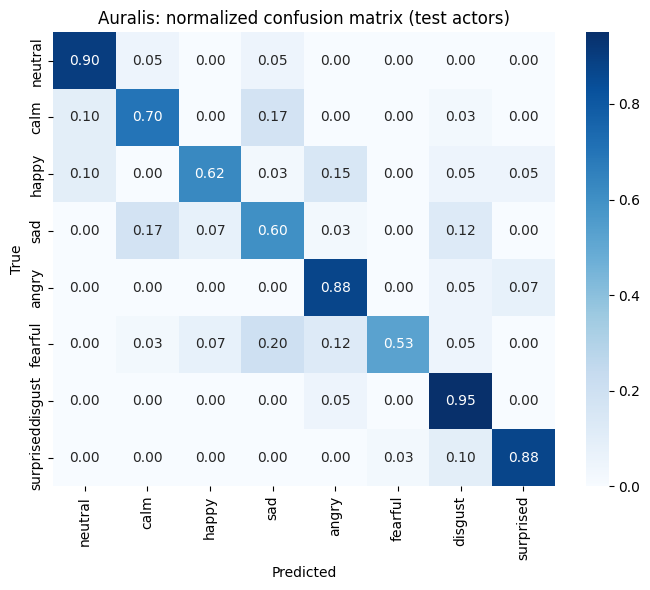

In [ ]:
ck = torch.load(BEST, map_location='cpu', weights_only=False)
model.load_state_dict(ck['model'])
print(f"Loaded best checkpoint from epoch {ck['epoch']} (val macro-F1 {ck['val_f1']:.4f})")

val_res  = evaluate(model, val_loader)
test_res = evaluate(model, test_loader)
print(f"\nVAL  | acc {val_res['acc']:.4f}  macro-F1 {val_res['f1']:.4f}  UAR {val_res['uar']:.4f}")
print(f"TEST | acc {test_res['acc']:.4f}  macro-F1 {test_res['f1']:.4f}  UAR {test_res['uar']:.4f}")
print(classification_report(test_res['labels'], test_res['preds'], target_names=LABELS, digits=3))

cm = confusion_matrix(test_res['labels'], test_res['preds'], normalize='true')
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Auralis: normalized confusion matrix (test actors)')
plt.tight_layout(); plt.savefig(DIRS['results'] / 'confusion_matrix_test.png', dpi=150); plt.show()

## 8. Robustness benchmark
The same test actors, with real-world degradations applied at test time. These numbers show how Auralis behaves outside clean studio audio.

robustness:   0%|          | 0/15 [00:00<?, ?it/s]

,scenario,acc,macro_f1,uar,acc_drop_vs_clean
0,clean,0.7467,0.7443,0.7562,0.0000
1,white noise 20 dB,0.7767,0.7662,0.7844,-0.0300
2,white noise 10 dB,0.7400,0.7265,0.7563,0.0067
3,white noise 5 dB,0.7033,0.6841,0.7219,0.0433
4,white noise 0 dB,0.6000,0.5651,0.6219,0.1467
5,pink noise 10 dB,0.7433,0.7355,0.7594,0.0033
6,brown noise 10 dB,0.7667,0.7647,0.7750,-0.0200
7,reverb RT60 0.4 s,0.7633,0.7530,0.7625,-0.0167
8,reverb RT60 0.8 s,0.6633,0.6555,0.6656,0.0833
9,telephone 300-3400 Hz,0.7233,0.7191,0.7281,0.0233


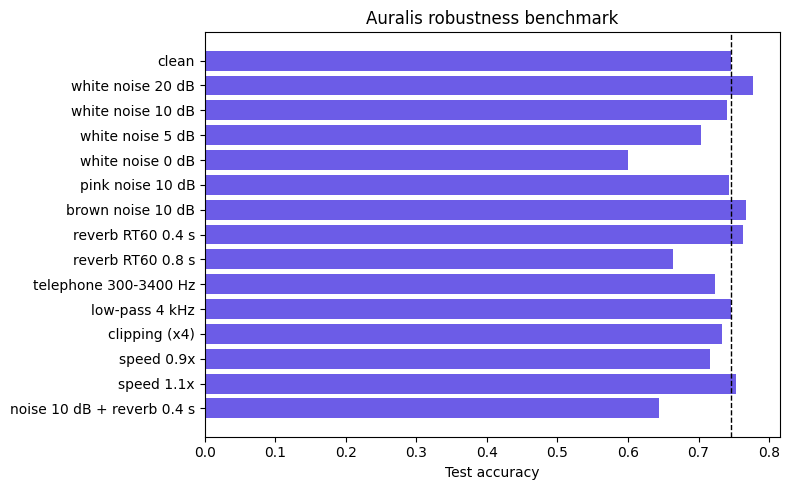

In [ ]:
rob = []
for name, fn in tqdm(robustness_scenarios().items(), desc='robustness'):
    r = evaluate(model, make_loader(w_te, y_te, corrupt=fn))
    rob.append(dict(scenario=name, acc=r['acc'], macro_f1=r['f1'], uar=r['uar']))
rob = pd.DataFrame(rob)
rob['acc_drop_vs_clean'] = rob.acc.iloc[0] - rob.acc
rob.to_csv(DIRS['results'] / 'robustness_test.csv', index=False)
display(rob.round(4))

plt.figure(figsize=(8, 5))
plt.barh(rob.scenario[::-1], rob.acc[::-1], color='#6C5CE7')
plt.axvline(rob.acc.iloc[0], color='k', ls='--', lw=1)
plt.xlabel('Test accuracy'); plt.title('Auralis robustness benchmark'); plt.tight_layout()
plt.savefig(DIRS['results'] / 'robustness_test.png', dpi=150); plt.show()

## 9. Save final artifacts and run an inference demo

In [ ]:
config = dict(name='Auralis', version='v1', backbone=CFG['backbone'], labels=LABELS, sample_rate=SR,
              max_sec=MAX_SEC, best_epoch=int(ck['epoch']))
json.dump(config, open(DIRS['best_model'] / 'auralis_config.json', 'w'), indent=2)

results = dict(config=CFG, split=dict(train_actors=train_actors, val_actors=val_actors, test_actors=test_actors),
               val={k: float(v) for k, v in val_res.items() if k in ('loss', 'acc', 'f1', 'uar')},
               test={k: float(v) for k, v in test_res.items() if k in ('loss', 'acc', 'f1', 'uar')},
               robustness=rob.to_dict(orient='records'))
json.dump(results, open(DIRS['results'] / 'final_results.json', 'w'), indent=2)
shutil.copy('/content/auralis_core.py', ROOT / 'auralis_core.py')
if LAST.exists():
    LAST.unlink()     # resume file (~1 GB) is no longer needed
print('Saved to', ROOT); print(*sorted(str(p.relative_to(ROOT)) for p in ROOT.rglob('*') if p.is_file()), sep='\n')

Saved to /content/drive/MyDrive/Auralis AI
auralis_core.py
best_model/auralis_best.pt
best_model/auralis_config.json
data/Audio_Speech_Actors_01-24.zip
data/RAVDESS/Actor_01/03-01-01-01-01-01-01.wav
data/RAVDESS/Actor_01/03-01-01-01-01-02-01.wav
data/RAVDESS/Actor_01/03-01-01-01-02-01-01.wav
data/RAVDESS/Actor_01/03-01-01-01-02-02-01.wav
data/RAVDESS/Actor_01/03-01-02-01-01-01-01.wav
data/RAVDESS/Actor_01/03-01-02-01-01-02-01.wav
data/RAVDESS/Actor_01/03-01-02-01-02-01-01.wav
data/RAVDESS/Actor_01/03-01-02-01-02-02-01.wav
data/RAVDESS/Actor_01/03-01-02-02-01-01-01.wav
data/RAVDESS/Actor_01/03-01-02-02-01-02-01.wav
data/RAVDESS/Actor_01/03-01-02-02-02-01-01.wav
data/RAVDESS/Actor_01/03-01-02-02-02-02-01.wav
data/RAVDESS/Actor_01/03-01-03-01-01-01-01.wav
data/RAVDESS/Actor_01/03-01-03-01-01-02-01.wav
data/RAVDESS/Actor_01/03-01-03-01-02-01-01.wav
data/RAVDESS/Actor_01/03-01-03-01-02-02-01.wav
data/RAVDESS/Actor_01/03-01-03-02-01-01-01.wav
data/RAVDESS/Actor_01/03-01-03-02-01-02-01.wav
da

In [ ]:
# Inference demo: this is exactly what the portal backend will do.
model_inf, cfg_inf = load_auralis(ROOT)
sample = df[df.split == 'test'].iloc[0]
out = predict(model_inf, cfg_inf, sample.path)
print('true:', sample.emotion, '| predicted:', out['emotion'], f"({out['confidence']:.2f})")
print(json.dumps(out['probabilities'], indent=2))

# Try your own voice (wav/mp3/m4a): uncomment
# from google.colab import files
# up = files.upload(); path = next(iter(up))
# print(predict(model_inf, cfg_inf, path))

true: neutral | predicted: neutral (0.89)
{
  "neutral": 0.8885130286216736,
  "calm": 0.0071115377359092236,
  "happy": 0.06125441938638687,
  "sad": 0.005921383388340473,
  "angry": 0.010599259287118912,
  "fearful": 0.0018502683378756046,
  "disgust": 0.007351325359195471,
  "surprised": 0.017398808151483536
}
